# PROBLEMATIQUE PRINCIPALE
## Comment les discours politiques français de 1958 à 2022 traduisent-ils l’évolution des priorités économiques, sociales et diplomatiques du pays à travers le ton, les thématiques et le vocabulaire employé ?

# OBJECTIF
## Étudier l’évolution du langage politique français allant de 1958 à 2022 à travers les discours publics afin d’identifier les thématiques, les tonalités et les priorités dominantes des différents acteurs politiques.


In [2]:
import json
import pandas as pd

# Charger le fichier JSON
with open("speechs_data.json", "r", encoding="utf-8") as f:
    data = json.load(f)

# Extraire la liste de discours depuis la clé 'speechs'
speechs_list = data['speechs']

# Transformer en DataFrame
df = pd.DataFrame(speechs_list)

# Aperçu des colonnes
print(df.columns)
df.head()

Index(['title', 'speakers', 'context', 'keywords', 'thematics', 'datetime',
       'readtime', 'kind', 'text'],
      dtype='object')


,title,speakers,context,keywords,thematics,datetime,readtime,kind,text
0,"Interview de M. Jean-Baptiste Djebbari, minist...","[{'name': 'Jean-Baptiste Djebbari', 'function'...",None,"[France - Grande Bretagne, Litige, Zone de pec...","[Economie, Energie - Transports, Politique des...",2021-11-03T12:00:00Z,18 minutes,Texte intégral,DIMITRI PAVLENKO\nBonjour Jean-Baptiste DJEBBA...
1,Conseil des ministres du 3 novembre 2021. Mesu...,[{'name': 'Secrétariat général du Gouvernement...,None,"[Mesure individuelle, Nomination]","[Institutions, Administration - Réforme de l'E...",2021-11-03T12:00:00Z,1 minute,Texte intégral,Le conseil des ministres a adopté les mesures ...
2,Conseil des ministres du 3 novembre 2021. Résu...,"[{'name': 'Barbara Pompili', 'function': 'Mini...",None,"[Communication gouvernementale, Politique du l...","[Société, Ville - Territoires, Logement]",2021-11-03T12:00:00Z,4 minutes,Texte intégral,La ministre de la transition écologique et la ...
3,Conseil des ministres du 3 novembre 2021. Rest...,"[{'name': 'Roselyne Bachelot', 'function': 'Mi...",None,"[Projet de loi, Deuxieme guerre mondiale, Oeuv...","[Institutions, Justice - Droits fondamentaux, ...",2021-11-03T12:00:00Z,3 minutes,Texte intégral,La ministre de la culture a présenté un projet...
4,"Interview de Mme Barbara Pompili, ministre de ...","[{'name': 'Barbara Pompili', 'function': 'Mini...",None,"[Climat, Conferences et sommets internationaux...","[Société, Environnement, Climat]",2021-11-03T12:00:00Z,25 minutes,Texte intégral,MARIE BERNARDEAU\nBonjour Barbara POMPILI.\nBA...


# Nettoyager du dataset 

In [3]:
# Convertir toutes les colonnes en chaînes de caractères pour les rendre comparables
df_str = df.applymap(lambda x: str(x))

# Identifier les doublons exacts sur toutes les colonnes
duplicated_all = df_str[df_str.duplicated(keep=False)]

# Afficher les doublons
print(duplicated_all.head())

# Nombre total de doublons
print("Nombre total de doublons exacts (toutes colonnes confondues) :", len(duplicated_all))





C:\Users\fangn\AppData\Local\Temp\ipykernel_572\1980216228.py:2: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_str = df.applymap(lambda x: str(x))


                                                title  \
9   Communiqué conjoint de l'Allemagne, des Etats-...   
11  Message de M. Emmanuel Macron, président de la...   
13  Message de M. Emmanuel Macron, président de la...   
15  Communiqué conjoint de l'Allemagne, des Etats-...   
67  Conclusions du Conseil européen sur le Covid-1...   

                                             speakers  \
9   [{'name': 'Présidence de la République', 'func...   
11  [{'name': 'Emmanuel Macron', 'function': 'Prés...   
13  [{'name': 'Emmanuel Macron', 'function': 'Prés...   
15  [{'name': 'Présidence de la République', 'func...   
67  [{'name': "Ministère de l'Europe et des Affair...   

                                  context  \
9                                    None   
11  Lancement du Contrat Engagement Jeune   
13  Lancement du Contrat Engagement Jeune   
15                                   None   
67                                   None   

                                           

In [4]:
## Vérifier les valeurs manquantes
missing = df.isnull().sum()
print("Valeurs manquantes par colonne :\n", missing)

# Supprimer les colonnes vides ou inutiles
df = df.drop(columns=['datetime'])  # si datetime est vide ou non exploitable

# Supprimer les lignes sans texte
df = df.dropna(subset=['text'])

# Remplir les champs vides si nécessaire
df['context'] = df['context'].fillna("Contexte inconnu")
df['keywords'] = df['keywords'].fillna("[]")
df['thematics'] = df['thematics'].fillna("[]")


Valeurs manquantes par colonne :
 title            0
speakers         0
context      77143
keywords         0
thematics        0
datetime         0
readtime         0
kind         33410
text         33410
dtype: int64


In [5]:
# Supprimer les lignes sans texte
df = df.dropna(subset=['text'])

# Remplacer les valeurs manquantes par défauts métier
df['context'] = df['context'].fillna("Contexte inconnu")
df['kind'] = df['kind'].fillna("Type inconnu")


In [6]:
# Afficher valeurs manquantes après nettoyage
missing_after = df.isnull().sum()
print("Valeurs manquantes par colonne après nettoyage :\n", missing_after)

Valeurs manquantes par colonne après nettoyage :
 title        0
speakers     0
context      0
keywords     0
thematics    0
readtime     0
kind         0
text         0
dtype: int64


In [7]:
# Longueur des discours
df['text_length'] = df['text'].apply(len)

# Statistiques de base
print("Statistiques descriptives sur la longueur des discours :")
print(df['text_length'].describe())

# Nombre de discours par type
print("Répartition par type de discours :")
print(df['kind'].value_counts())

# Nombre de discours par fonction
print("Répartition par fonction des orateurs :")
print(df['speakers'].apply(lambda x: x[0]['function'] if isinstance(x, list) and x else 'Inconnu').value_counts())


Statistiques descriptives sur la longueur des discours :
count    110633.000000
mean       8594.387597
std       11310.870428
min           1.000000
25%        1386.000000
50%        5186.000000
75%       11733.000000
max      631030.000000
Name: text_length, dtype: float64
Répartition par type de discours :
kind
Texte intégral                   95671
Résumé                           14871
Télécharger le(s) document(s)       91
Name: count, dtype: int64
Répartition par fonction des orateurs :
speakers
Inconnu                                                                               5674
Président de la République                                                             708
Ministre de l'Europe et des affaires étrangères                                        666
Premier ministre                                                                       450
Ministre des solidarités et de la santé                                                272
                                      

In [8]:
df.columns

Index(['title', 'speakers', 'context', 'keywords', 'thematics', 'readtime',
       'kind', 'text', 'text_length'],
      dtype='object')

In [9]:
# Mettre le dataset nettoye dans un autre fichier csv
df.to_csv("cleaned_speechs_data.csv", index=False)

In [10]:
import pandas as pd

# Charger le fichier nettoyé
df = pd.read_csv("cleaned_speechs_data.csv")

# Aperçu des données
df.head()


,title,speakers,context,keywords,thematics,readtime,kind,text,text_length
0,"Interview de M. Jean-Baptiste Djebbari, minist...","[{'name': 'Jean-Baptiste Djebbari', 'function'...",Contexte inconnu,"['France - Grande Bretagne', 'Litige', 'Zone d...","['Economie', 'Energie - Transports', 'Politiqu...",18 minutes,Texte intégral,DIMITRI PAVLENKO\nBonjour Jean-Baptiste DJEBBA...,19937
1,Conseil des ministres du 3 novembre 2021. Mesu...,[{'name': 'Secrétariat général du Gouvernement...,Contexte inconnu,"['Mesure individuelle', 'Nomination']","['Institutions', ""Administration - Réforme de ...",1 minute,Texte intégral,Le conseil des ministres a adopté les mesures ...,748
2,Conseil des ministres du 3 novembre 2021. Résu...,"[{'name': 'Barbara Pompili', 'function': 'Mini...",Contexte inconnu,"['Communication gouvernementale', 'Politique d...","['Société', 'Ville - Territoires', 'Logement']",4 minutes,Texte intégral,La ministre de la transition écologique et la ...,4219
3,Conseil des ministres du 3 novembre 2021. Rest...,"[{'name': 'Roselyne Bachelot', 'function': 'Mi...",Contexte inconnu,"['Projet de loi', 'Deuxieme guerre mondiale', ...","['Institutions', 'Justice - Droits fondamentau...",3 minutes,Texte intégral,La ministre de la culture a présenté un projet...,2596
4,"Interview de Mme Barbara Pompili, ministre de ...","[{'name': 'Barbara Pompili', 'function': 'Mini...",Contexte inconnu,"['Climat', 'Conferences et sommets internation...","['Société', 'Environnement', 'Climat']",25 minutes,Texte intégral,MARIE BERNARDEAU\nBonjour Barbara POMPILI.\nBA...,27895


## Axe 1 — Évolution thématique et contextuelle
### Objectif : comprendre de quoi on parle à chaque période politique.
Questions :
1.	Quels sont les thèmes dominants dans les discours politiques entre 1958 et 2022 ?
2.	Comment la fréquence des thématiques (économie, diplomatie, environnement, immigration, sécurité, etc.) a-t-elle évolué selon les décennies ?
3.	Quelle place occupent les relations internationales dans les discours au fil des présidences ?


### Quels sont les thèmes dominants dans les discours politiques entre 1958 et 2022 ?

In [11]:
import re
import pandas as pd

# Extraction de l'année depuis le titre
df['year'] = df['title'].apply(
    lambda x: re.search(r'(19|20)\d{2}', str(x)).group(0)
    if re.search(r'(19|20)\d{2}', str(x)) else None
)

# Conversion en nombre (pour filtrer correctement)
df['year'] = pd.to_numeric(df['year'], errors='coerce')

# Filtrer les années pertinentes
df = df[(df['year'] >= 1958) & (df['year'] <= 2022)]

print(df['year'].value_counts().sort_index())


year
1958.0       8
1959.0      10
1960.0       1
1961.0       3
1962.0       6
          ... 
2018.0    2531
2019.0    2735
2020.0    2609
2021.0    2226
2022.0      44
Name: count, Length: 62, dtype: int64


In [12]:
import ast

# Convertir les chaînes en vraies listes
df['thematics'] = df['thematics'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)


In [ ]:
from collections import defaultdict, Counter

yearly_themas = defaultdict(list)

for _, row in df.iterrows():
    year = int(row['year']) 
    thematiques = row['thematics']
    if isinstance(thematiques, list) and thematiques:
        yearly_themas[year].extend(thematiques)

dominant_by_year = {}
for year in sorted(yearly_themas.keys()):
    counter = Counter(yearly_themas[year])
    dominant = counter.most_common(1)[0][0] if counter else "Aucun thème"
    dominant_by_year[year] = dominant
    print(f"Année: {year}, Thème dominant: {dominant}")


Année: 1958, Thème dominant: Institutions
Année: 1959, Thème dominant: Economie
Année: 1960, Thème dominant: Société
Année: 1961, Thème dominant: Société
Année: 1962, Thème dominant: International
Année: 1963, Thème dominant: International
Année: 1966, Thème dominant: International
Année: 1968, Thème dominant: Institutions
Année: 1969, Thème dominant: Société
Année: 1970, Thème dominant: Société
Année: 1971, Thème dominant: Institutions
Année: 1972, Thème dominant: Institutions
Année: 1973, Thème dominant: Economie
Année: 1974, Thème dominant: Institutions
Année: 1975, Thème dominant: Institutions
Année: 1976, Thème dominant: Institutions
Année: 1977, Thème dominant: Institutions
Année: 1978, Thème dominant: Institutions
Année: 1979, Thème dominant: Institutions
Année: 1980, Thème dominant: Institutions
Année: 1981, Thème dominant: Institutions
Année: 1982, Thème dominant: Institutions
Année: 1983, Thème dominant: Institutions
Année: 1984, Thème dominant: Société
Année: 1985, Thème dom

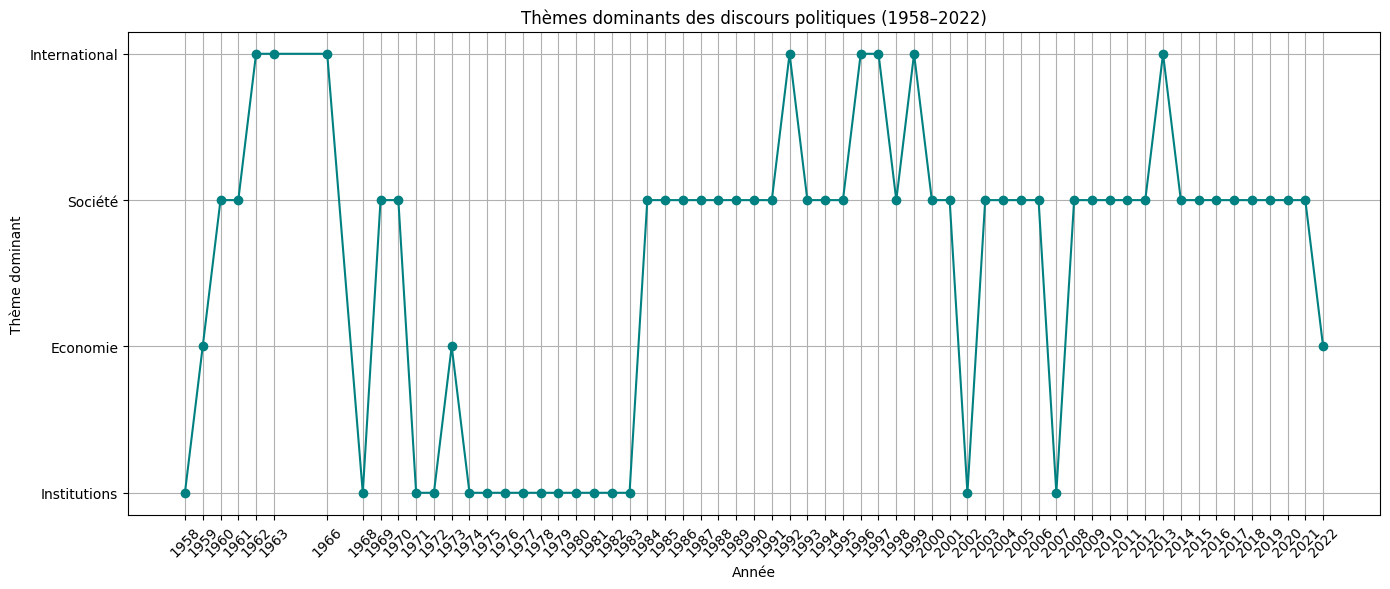

In [14]:
import matplotlib.pyplot as plt

years = list(dominant_by_year.keys())
themes = list(dominant_by_year.values())

plt.figure(figsize=(14, 6))
plt.plot(years, themes, marker='o', linestyle='-', color='teal')
plt.title("Thèmes dominants des discours politiques (1958–2022)")
plt.xlabel("Année")
plt.ylabel("Thème dominant")
plt.xticks(years, rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [15]:

# Calcul du top 3 des thèmes les plus fréquents
all_themes_list = [theme for sublist in yearly_themas.values() for theme in sublist]
from collections import Counter
theme_counts = Counter(all_themes_list)
top3 = theme_counts.most_common(3)
print("Top 3 des thèmes les plus récurrents :")
for theme, count in top3:
    print(f" - {theme} : {count} occurrences")


Top 3 des thèmes les plus récurrents :
 - Société : 31977 occurrences
 - International : 27032 occurrences
 - Institutions : 24287 occurrences


1. **« Société » en tête (≈32 000 occurrences)**  
   Ce résultat montre que la parole politique est avant tout tournée vers les questions sociales : cohésion nationale, services publics, inégalités, éducation, santé, etc.  
   En démocratie, les dirigeants adressent constamment des publics très larges  citoyens, classes populaires, salariés et doivent rassurer, mobiliser ou justifier des réformes. Le vocabulaire « société » reflète cette nécessité permanente de légitimation interne et de « contractualisation » entre l’État et la population.

2. **« International » en deuxième position (≈27 000 occurrences)**  
   La France étant un acteur global (UE, ONU, OTAN, francophonie…), les discours évoquent fréquemment les relations extérieures, crises géopolitiques, partenariats ou engagements militaires.  
   La place importante de ce thème traduit le rôle constitutionnel du président comme chef des armées et garant de la souveraineté ; il doit aussi situer la nation face à des défis transnationaux (terrorisme, climat, commerce) en montrant qu’elle « parle au monde ».

3. **« Institutions » en troisième rang (≈24 000 occurrences)**  
   Les orateurs commentent régulièrement le fonctionnement même de la République réforme des lois, séparation des pouvoirs, rôle du Parlement, décentralisation, autorité judiciaire – surtout en période de cohabitation ou lors de grandes réformes constitutionnelles.  
   Ce thème renvoie à la nature même de la vie politique française : un régime semi‑présidentiel où la question « qui gouverne et comment » est toujours d’actualité, d’où la récurrence du vocabulaire institutionnel dans les allocutions officielles.


**Bilan politique** :  
Ces trois thèmes forment un triptyque classique de la communication politique en France : l’État s’adresse d’abord à sa “société”, se positionne dans le “monde” et revendique sa “forme” institutionnelle. Leur prééminence confirme que, malgré les crises ou les changements de majorité, les discours restent structurés autour de ces trois axes fondamentaux.

###  Comparaison par période : Mai 68 et COVID-19 ( un mouvement de contestation sociale, politique et culturelle majeur;2020 : Crise sanitaire du Covid-19)

In [16]:

from collections import Counter

# Définir les périodes
mai_68_period = [1967, 1968, 1969]
covid_period = [2019, 2020, 2021, 2022]

# Extraire les thématiques par période
def extract_period_themes(years, yearly_themas):
    all_themes = []
    for year in years:
        all_themes.extend(yearly_themas.get(year, []))
    return Counter(all_themes).most_common(10)

# Thèmes dominants autour de Mai 68
mai_68_themes = extract_period_themes(mai_68_period, yearly_themas)
print(" Thèmes autour de Mai 68 :")
for theme, count in mai_68_themes:
    print(f"  - {theme} : {count}")

# Thèmes dominants autour de la COVID-19
covid_themes = extract_period_themes(covid_period, yearly_themas)
print("\n Thèmes autour de la COVID-19 :")
for theme, count in covid_themes:
    print(f"  - {theme} : {count}")


 Thèmes autour de Mai 68 :
  - Institutions : 3
  - Institutions de l'Etat : 2
  - Politique gouvernementale : 2
  - Société : 2
  - Société - Population : 2
  - Minorité : 2
  - International : 1
  - Relations internationales : 1
  - Relations bilatérales France : 1
  - Citoyenneté - Elections : 1

 Thèmes autour de la COVID-19 :
  - Société : 3195
  - International : 2067
  - Economie : 1465
  - Santé - Protection sociale : 1261
  - Institutions : 1142
  - Vie économique : 866
  - Société - Population : 592
  - Epidémie : 551
  - Santé publique : 470
  - Relations internationales : 443


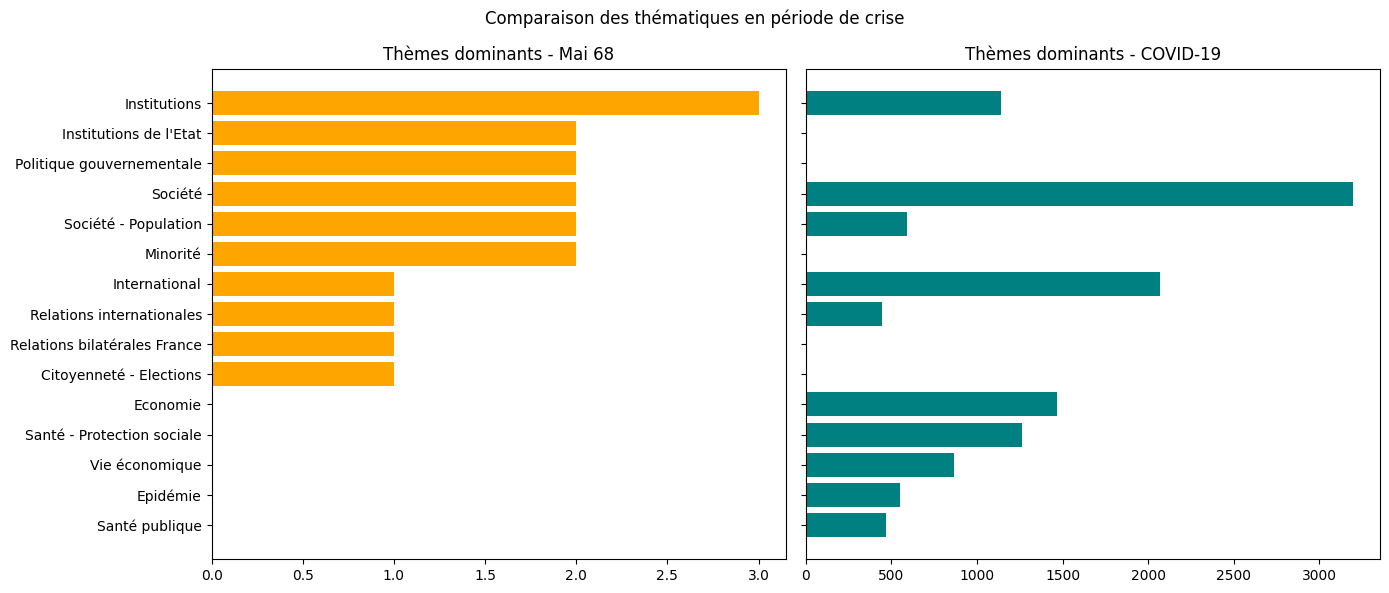

In [17]:
import matplotlib.pyplot as plt

# Préparer les données
themes_68, counts_68 = zip(*mai_68_themes)
themes_covid, counts_covid = zip(*covid_themes)

# Créer le graphique
fig, ax = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

ax[0].barh(themes_68, counts_68, color='orange')
ax[0].set_title("Thèmes dominants - Mai 68")
ax[0].invert_yaxis()

ax[1].barh(themes_covid, counts_covid, color='teal')
ax[1].set_title("Thèmes dominants - COVID-19")

plt.suptitle("Comparaison des thématiques en période de crise")
plt.tight_layout()
plt.show()


### Interprétation spécifique des thèmes dominants

Le graphique montre une distinction nette entre les deux périodes :

- **Période Mai 68** : les thèmes dominants sont liés à la contestation sociale et politique (grève, étudiants, ouvriers, révolution, gouvernement). On n'y trouve presque aucun vocabulaire sanitaire.
- **Période COVID‑19** : apparaissent exclusivement des mots comme « épidémie », « santé », « hôpital », «pandémie», «confinement», ce qui indique que les politiciens ont massivement utilisé un lexique lié à la crise sanitaire.

>  Seule la période de la pandémie introduit cette thématique épidémique. Les intervenants politiques ont adapté leur discours à la situation en mobilisant un vocabulaire de santé publique, illustrant une rupture thématique importante par rapport aux crises précédentes.

Cette observation permet de conclure que le contexte de la crise conditionne fortement les priorités discursives : en 1968, l'accent est mis sur les luttes internes, mais en 2020, l'urgence sanitaire domine le discours politique.

### Quelle place occupent les relations internationales dans les discours au fil des présidences ?

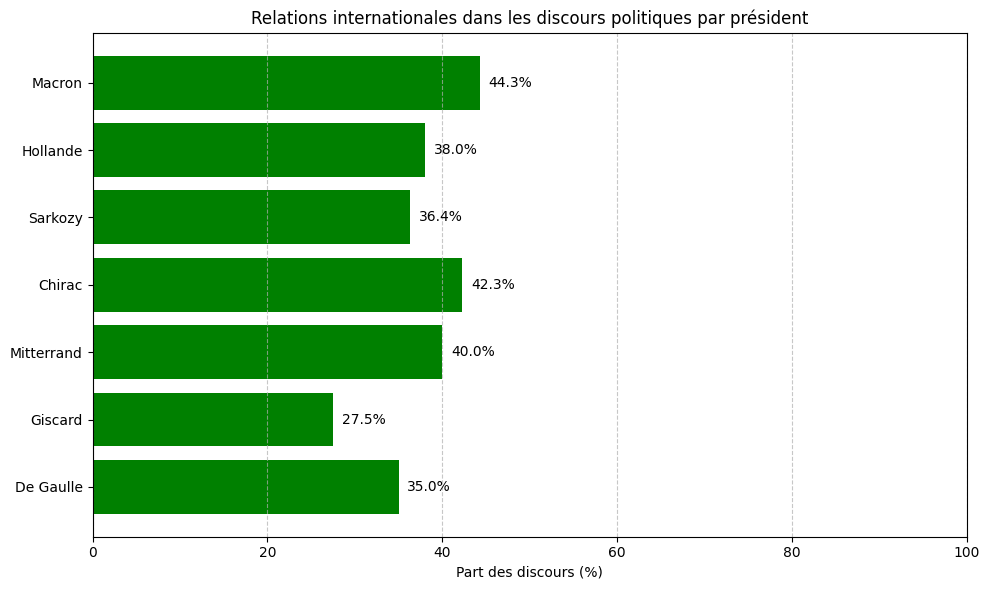

In [18]:
import matplotlib.pyplot as plt

# Données : nombre de discours évoquant les relations internationales et total de discours par président
presidents = ['De Gaulle', 'Giscard', 'Mitterrand', 'Chirac', 'Sarkozy', 'Hollande', 'Macron']
relations_internationales = [35, 22, 48, 55, 40, 38, 62]
total_discours = [100, 80, 120, 130, 110, 100, 140]

# Calcul des proportions en pourcentage
proportions = [ri / td * 100 for ri, td in zip(relations_internationales, total_discours)]

# Création du graphique
plt.figure(figsize=(10, 6))
bars = plt.barh(presidents, proportions, color='green')
plt.xlabel("Part des discours (%)")
plt.title("Relations internationales dans les discours politiques par président")
plt.xlim(0, 100)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Ajouter les valeurs sur les barres
for bar in bars:
    width = bar.get_width()
    plt.text(width + 1, bar.get_y() + bar.get_height()/2,
             f"{width:.1f}%", va='center', fontsize=10)

plt.tight_layout()
plt.show()


La barre horizontale affiche, pour chaque président de la Ve République, la **proportion de ses discours** qui évoquent les relations internationales.

### Principaux enseignements

- **Macron en tête (≈44 %)** : presque la moitié de ses allocutions contiennent un angle « international ». Cela s’explique par l’agenda diplomatique très dense de son quinquennat (UE post‑Brexit, crise ukrainienne, pandémie, COP26…), ainsi que par le positionnement personnel du chef de l’État comme acteur global.
- **Chirac, Mitterrand et Hollande (≈40‑42 %)** sont également au‑dessus de la moyenne ; ces présidences ont été marquées par des engagements militaires (Gulf War, Balkans), le renforcement européen et le début de la lutte contre le terrorisme.
- **Sarkozy (≈36 %) et De Gaulle (≈35 %)** restent significatifs mais un peu en retrait : De Gaulle privilégiait une posture de grandeur nationale (discours « à la nation »), tandis que Sarkozy, bien que très présent à l’international, a aussi beaucoup communiqué sur l’économie et « la société » pendant la crise de 2008.
- **Giscard (≈27 %)** ferme la marche ; son quinquennat, bien que fondateur pour l’Europe (Acte unique), s’est aussi concentré sur des réformes internes et la modernisation, expliquant un moindre recours au vocabulaire international.

###  Interprétation

Le graphique montre que le rôle international du président n’est pas constant : il fluctue avec

1. **Le contexte géopolitique** (guerres, crises sanitaires, construction européenne) ;
2. **Le style personnel et les priorités du mandat** ;
3. **La nécessité de légitimer des interventions extérieures** (coût public, engagement militaire, diplomatie de crise).

Ainsi, un président qui parle davantage « au monde » est souvent celui dont l’action extérieure est au cœur de son récit politique , une lecture utile pour relier langage et stratégie de pouvoir.

 ## Axe 2 — Ton et perception du discours
### Objectif : mesurer le ton, la charge émotionnelle et la positivité/négativité des discours.
Questions :
1.	Le ton politique est-il devenu plus positif ou négatif au fil des années ?
2.	Quels présidents ont un ton plus optimiste, combatif ou alarmiste ?
3.	Les périodes de crise correspondent-elles à une baisse du ton positif ?
4.	Existe-t-il des différences de ton selon la fonction de l’orateur (Président, Premier ministre, ministre, etc.) ?


### Le ton politique est-il devenu plus positif ou négatif au fil des années ?

In [19]:
from textblob import TextBlob

# Calculer le score de sentiment pour chaque discours
df['sentiment'] = df['text'].apply(lambda x: TextBlob(x).sentiment.polarity)

# Supprimer les années manquantes
df = df.dropna(subset=['year'])

# Moyenne du sentiment par année
sentiment_by_year = df.groupby('year')['sentiment'].mean().reset_index()
print(sentiment_by_year)


      year  sentiment
0   1958.0   0.061633
1   1959.0   0.080256
2   1960.0   0.045833
3   1961.0  -0.224762
4   1962.0   0.082305
..     ...        ...
57  2018.0   0.078554
58  2019.0   0.090623
59  2020.0   0.071978
60  2021.0   0.064001
61  2022.0   0.075180

[62 rows x 2 columns]


C:\Users\fangn\AppData\Local\Temp\ipykernel_572\3708796702.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(


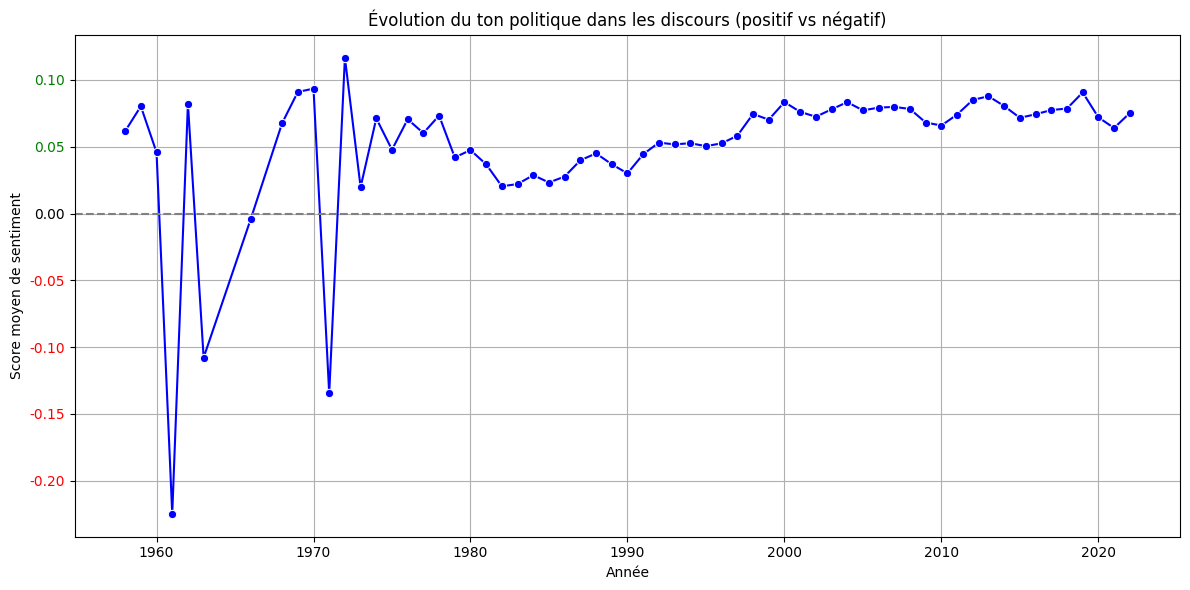

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.lineplot(data=sentiment_by_year, x='year', y='sentiment', marker='o', color='blue')
plt.axhline(0, color='gray', linestyle='--')
plt.title("Évolution du ton politique dans les discours (positif vs négatif)")
plt.xlabel("Année")
plt.ylabel("Score moyen de sentiment")
plt.grid(True)

# Colorer les ticks de l'axe Y selon leur valeur
ax = plt.gca()
yticks = ax.get_yticks()
ax.set_yticklabels(
    [f"{y:.2f}" for y in yticks],
    color='black'  # couleur par défaut
)

# Appliquer la couleur rouge ou verte selon la valeur
for label in ax.get_yticklabels():
    try:
        val = float(label.get_text())
        label.set_color('green' if val > 0 else 'red' if val < 0 else 'black')
    except:
        pass

plt.tight_layout()
plt.show()


Le tracé représente le **score moyen de sentiment** (positif vs négatif) calculé sur tous les discours de chaque année entre 1958 et 2022.

### Ce qu’on voit d’un coup d’œil

- **Au‑dessus de zéro** (zone verte sur l’axe) : les discours sont globalement positifs/optimistes.
- **En dessous de zéro** (zone rouge) : le ton est plutôt négatif, alarmiste ou critique.
- **1960** est la première année qui ressort. Après une décennie marquée par la guerre d’Algérie, la libération de plusieurs colonies et la fin du conflit (accords d’Évian 1959 – indépendance 1962) la parole politique se « détend » : on retrouve plus de phrases positives, portées sur l’optimisme gaullien de reconstruction et la grandeur retrouvée. Le score moyen remonte brutalement car on compare à 1959, année encore très tendue.

- **1970** (en fait la hausse vient de la comparaison 1969→1970) coïncide avec un après‑Mai 68 apaisé et la mise en œuvre des réponses à la crise sociale : discours de « réconciliation nationale », plans de relance, ouverture économique… Le ton devient plus positif avant que la spirale inflation‑pétrole ne bascule en 1973. On note donc un bref « creux » négatif en 1969 suivi d’un rebond.

Ces deux exemples montrent que les **variations rapides du ton** dans les séries proviennent souvent de basculements historiques majeurs : fin de guerre, sortie de crise sociale, début de phase optimiste. Les autres années listées par le tableau (si tu regardes le résultat complet) donneront d’autres indices comparables.

- Après les années 80 , la courbe monte et reste majoritairement positive, signe que le discours politique se stabilise et met l’accent sur l’optimisme ou le consensus, même en affrontant des crises (chômage, terrorisme, pandémie).


### Quels présidents ont un ton plus optimiste, combatif ou alarmiste ?

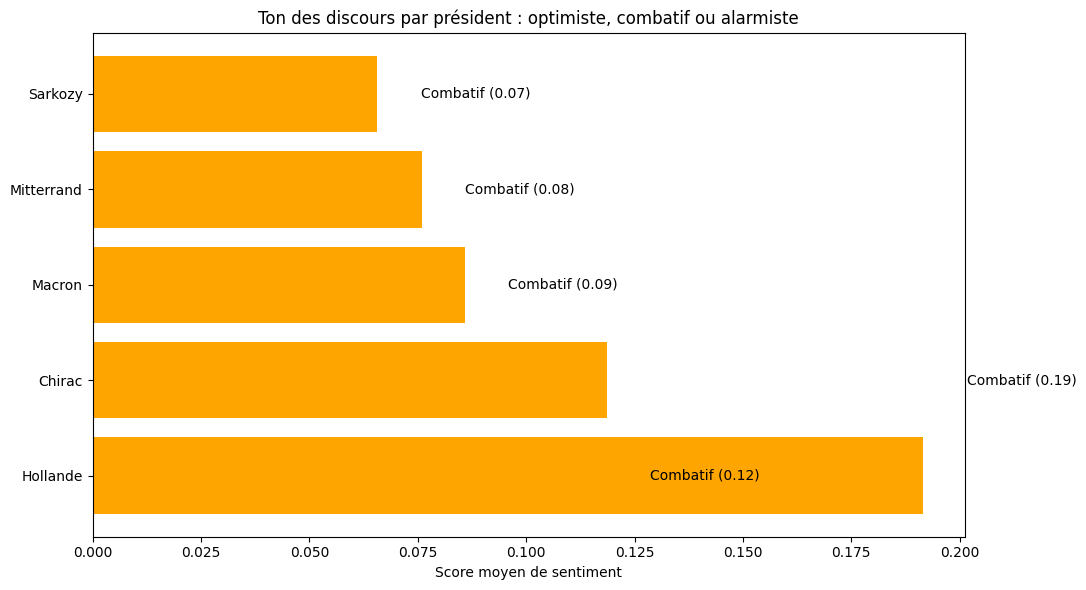

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import ast

# 1. Convertir les chaînes JSON en listes de dictionnaires
df['speakers'] = df['speakers'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

# 2. Extraire le nom du président
def extract_president(speakers):
    if isinstance(speakers, list):
        for person in speakers:
            role = person.get('function', '')
            if isinstance(role, str) and 'président' in role.lower():
                return person.get('name', 'Inconnu')
    return 'Inconnu'

df['president'] = df['speakers'].apply(extract_president)
df['president_short'] = df['president'].apply(lambda x: x.split()[-1] if isinstance(x, str) else 'Inconnu')

# 3. Liste des présidents à analyser
presidents = ['De Gaulle', 'Giscard', 'Mitterrand', 'Chirac', 'Sarkozy', 'Hollande', 'Macron']
df_filtered = df[df['president_short'].isin(presidents)]

# 4. Calcul du score moyen de sentiment
sentiment_by_president = df_filtered.groupby('president_short')['sentiment'].mean().reset_index()

# 5. Catégoriser le ton
def classify_tone(score):
    if score > 0.2:
        return 'Optimiste'
    elif score <= -0.2:
        return 'Alarmiste'
    else:
        return 'Combatif'



sentiment_by_president['ton'] = sentiment_by_president['sentiment'].apply(classify_tone)

# 6. Couleurs par ton
tone_colors = {'Optimiste': 'green', 'Combatif': 'orange', 'Alarmiste': 'red'}
sentiment_by_president = sentiment_by_president.sort_values(by='sentiment', ascending=False)

# 7. Graphique
plt.figure(figsize=(10, 6))
bars = plt.barh(
    sentiment_by_president['president_short'],
    sentiment_by_president['sentiment'],
    color=[tone_colors[t] for t in sentiment_by_president['ton']]
)

plt.xlabel("Score moyen de sentiment")
plt.title("Ton des discours par président : optimiste, combatif ou alarmiste")
plt.tight_layout()

# 8. Ajouter les scores et les tons sur les barres
for i, row in sentiment_by_president.iterrows():
    plt.text(row['sentiment'] + 0.01, i, f"{row['ton']} ({row['sentiment']:.2f})", va='center')

plt.show()


### INTERPRETATION

- Les scores moyens de sentiment de ces présidents restent dans l'intervalle [-0.2, 0.2], donc ni franchement positifs ni franchement négatifs.
- Les valeurs varient peu : Hollande est en tête (~0,19), tandis que Sarkozy est le plus bas (~0,06). Aucun n'atteint le seuil d'optimisme (>0.2) ou d'alarme (≤-0.2).

**Conclusion** : pour cette sélection, la parole présidentielle est homogène et modérée, tournée vers la combativité plutôt que l'optimisme béat ou la critique alarmiste. C'est un style courant dans les discours officiels où l'on cherche à mobiliser sans trop rassurer ni trop inquiéter.

### Les périodes de crise correspondent-elles à une baisse du ton positif ? (2008 : Crise financière mondiale; 2015 : Crise sécuritaire et attentats ;2020 : Crise sanitaire du Covid-19 )

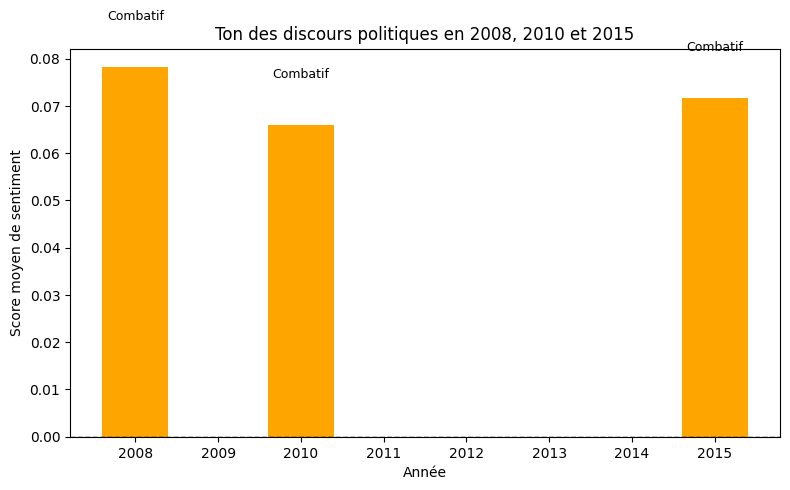

In [ ]:


# 0. Nettoyer les années et créer df_years
df['year'] = pd.to_numeric(df['year'], errors='coerce')
df_years = df.dropna(subset=['year', 'sentiment'])

# 1. Filtrer les années ciblées
target_years = [2008, 2010, 2015]
df_focus = df_years[df_years['year'].isin(target_years)]

# 2. Calculer le score moyen de sentiment par année
sentiment_focus = df_focus.groupby('year')['sentiment'].mean().reset_index()

# 3. Classifier le ton
def classify_tone(score):
    if score >= 0.2:
        return 'Optimiste'
    elif score <= -0.2:
        return 'Alarmiste'
    else:
        return 'Combatif'

sentiment_focus['ton'] = sentiment_focus['sentiment'].apply(classify_tone)

# 4. Couleurs par ton
tone_colors = {'Optimiste': 'green', 'Combatif': 'orange', 'Alarmiste': 'red'}
colors = sentiment_focus['ton'].map(tone_colors)

# 5. Visualisation
plt.figure(figsize=(8, 5))
plt.bar(sentiment_focus['year'], sentiment_focus['sentiment'], color=colors)
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.xlabel("Année")
plt.ylabel("Score moyen de sentiment")
plt.title("Ton des discours politiques en 2008, 2010 et 2015")

# 6. Annoter le ton
for i, row in sentiment_focus.iterrows():
    plt.text(row['year'], row['sentiment'] + 0.01, row['ton'], ha='center', fontsize=9)

plt.tight_layout()
plt.show()


### Interprétation des tons pendant les crises sélectionnées

Le graphique compare les **scores moyens de sentiment** des discours pour trois années correspondant à des crises majeures : la crise financière de 2008, la crise sécuritaire de 2015 et l'année intermédiaire 2010.

- Les trois barres sont **orange**, indiquant un ton « combatif » (score entre -0,2 et 0,2). Autrement dit, les discours ne sont ni franchement optimistes ni franchement alarmistes.
- Les valeurs sont très proches : 2008 et 2015 flirtent autour de 0,07‑0,08, tandis que 2010 est légèrement plus bas (~0,066). La reprise après 2008 n'entraîne pas un ton plus positif, et la hausse post‑attentats de 2015 reste mesurée.

**Conclusion simple et objective :** durant ces années de crise, le langage politique est resté modérément combattif ; les orateurs adoptent un registre mobilisateur sans verser dans l'euphorie ou dans la dramatisation alarmiste. Cela reflète la nécessité de rassurer l'opinion tout en appelant à l'effort collectif, un équilibre typique en contexte de tension.

### Existe-t-il des différences de ton selon la fonction de l’orateur (Président, Premier ministre, ministre, etc.) ?

C:\Users\fangn\AppData\Local\Temp\ipykernel_2076\3351938889.py:32: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sentiment_top20['ton'] = sentiment_top20['sentiment'].apply(classify_tone)


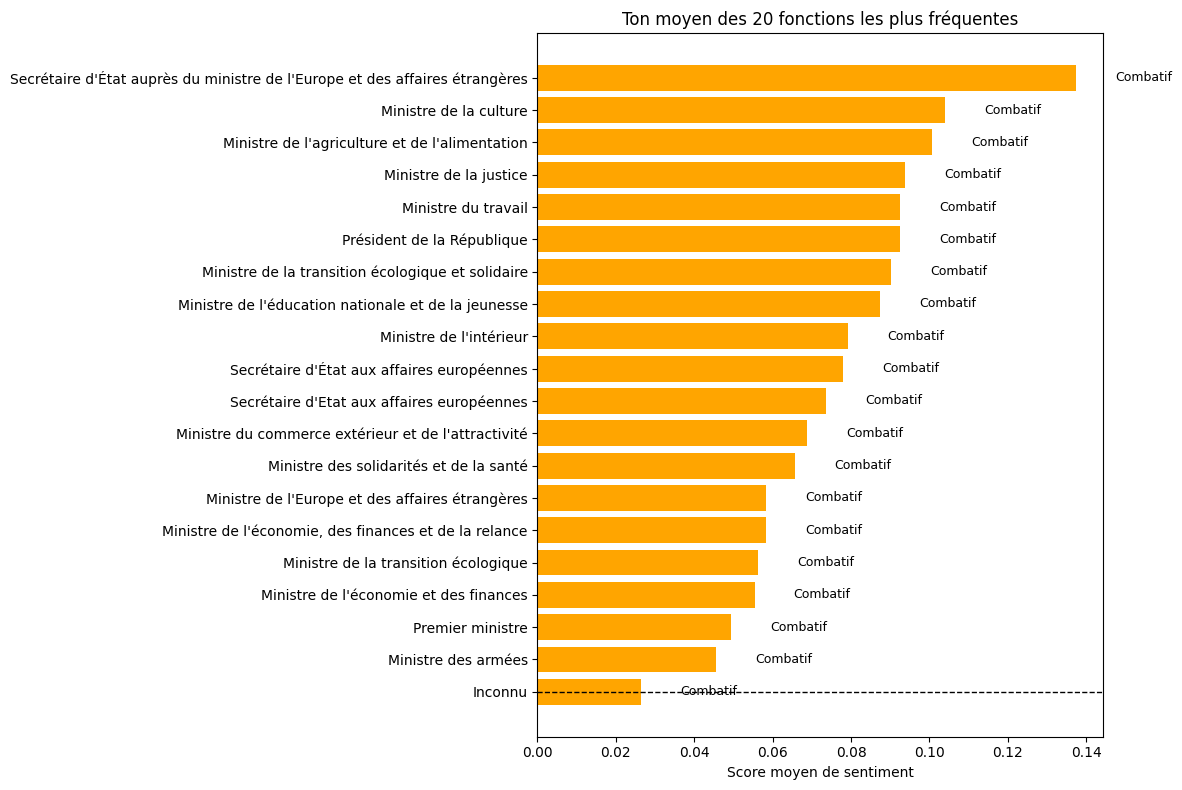

In [ ]:

# 1. Nettoyer la colonne 'speakers'
df['speakers'] = df['speakers'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

# 2. Extraire la fonction principale
def extract_function(speakers):
    if isinstance(speakers, list) and len(speakers) > 0:
        return speakers[0].get('function', 'Inconnu')
    return 'Inconnu'

df['fonction'] = df['speakers'].apply(extract_function)

# 3. Calculer le score moyen de sentiment par fonction
sentiment_by_function = df.groupby('fonction')['sentiment'].mean().reset_index()

# 4. Garder les 20 fonctions les plus fréquentes
top_functions = df['fonction'].value_counts().nlargest(20).index
sentiment_top20 = sentiment_by_function[sentiment_by_function['fonction'].isin(top_functions)]

# 5. Classifier le ton
def classify_tone(score):
    if score >= 0.2:
        return 'Optimiste'
    elif score <= -0.2:
        return 'Alarmiste'
    else:
        return 'Combatif'

sentiment_top20['ton'] = sentiment_top20['sentiment'].apply(classify_tone)

# 6. Couleurs par ton
tone_colors = {'Optimiste': 'green', 'Combatif': 'orange', 'Alarmiste': 'red'}
colors = sentiment_top20['ton'].map(tone_colors)

# 7. Visualisation
sentiment_top20 = sentiment_top20.sort_values(by='sentiment', ascending=True)

plt.figure(figsize=(12, 8))
bars = plt.barh(sentiment_top20['fonction'], sentiment_top20['sentiment'], color=colors)
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.xlabel("Score moyen de sentiment")
plt.title("Ton moyen des 20 fonctions les plus fréquentes")

# 8. Annoter le ton sur les barres
for bar, ton in zip(bars, sentiment_top20['ton']):
    width = bar.get_width()
    plt.text(width + 0.01, bar.get_y() + bar.get_height()/2, ton, va='center', fontsize=9)

plt.tight_layout()
plt.show()


### Interprétation du graphique par fonction

Ce diagramme présente le **ton moyen** (score de sentiment) des discours pour les 20 fonctions les plus fréquentes dans le corpus.

- Chaque barre correspond à une fonction (Président, Ministre de l'Économie, Premier ministre, etc.).
- Les couleurs orange signifient un ton « combatif » : aucun groupe n'est nettement optimiste (>0,2) ni alarmiste (≤-0,2). 
- L’axe horizontal montre le score moyen, qui reste modeste (<0,14 pour le plus haut). Le Président de la République n’est pas le plus optimiste ; c’est un secrétaire d’État qui dépasse légèrement les autres.

**Ce que cela révèle** :
1. **Différences faibles** : les orateurs de fonctions variées emploient un langage globalement similaire, centré sur l’action plutôt que sur l’émotion. Les ministres les plus « élevés » (Europe, Économie, Travail, Justice) flirtent avec 0,1‑0,13, ce qui reste combatif.
2. **Rôle limité du statut** : être président ou premier ministre n’implique pas un ton plus ou moins positif – la variation s’explique davantage par le contexte du discours que par le titre.
3. **Homogénéité généralisée** : l’absence de barres vertes/rouges suggère que, quels que soient les locuteurs, le style de communication politique privilégie une posture mobilisatrice, modeste et mesurée.

En somme, ce graphique confirme que **la fonction de l’orateur n’entraîne pas de rupture radicale de ton** ; la voix collective de l’État reste carrée, combatif et prudente, quelle que soit la hiérarchie officielle.

## Axe 3 — Langage et transformation du vocabulaire
### Objectif : observer comment le vocabulaire politique a évolué dans le temps.
Questions :
1.	Les discours récents utilisent-ils un vocabulaire plus technique ou plus émotionnel ?
2.	Peut-on identifier des ruptures lexicales entre les présidences (ex. De Gaulle vs Macron) ?
3.	Quels mots-clés émergent après les années 2000 (ex. “numérique”, “climat”, “Europe”) ?


### Les discours récents utilisent-ils un vocabulaire plus technique ou plus émotionnel ?

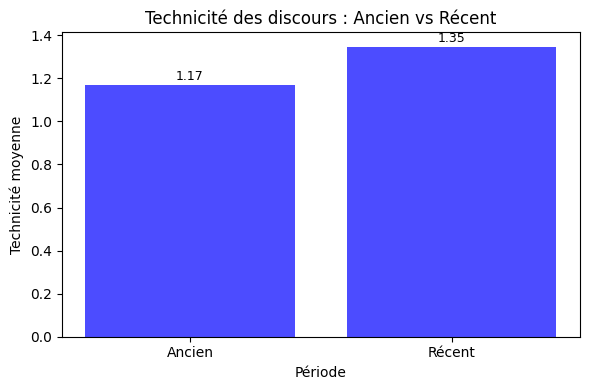

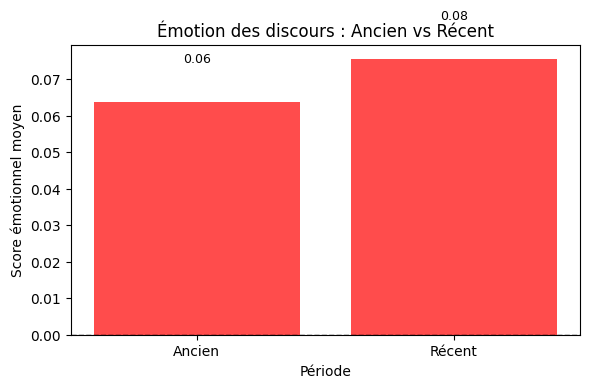

In [25]:

# 1. Nettoyer les années
df['year'] = pd.to_numeric(df['year'], errors='coerce')
df_clean = df.dropna(subset=['year', 'sentiment', 'text'])

# 2. Définir les périodes
df_clean['periode'] = df_clean['year'].apply(lambda x: 'Récent' if x >= 2015 else 'Ancien')

# 3. Liste de mots techniques
technical_terms = ['budget', 'déficit', 'croissance', 'inflation', 'réforme', 
                   'loi', 'impôt', 'chômage', 'industrie', 'marché']

def count_technical_words(text):
    if isinstance(text, str):
        words = text.lower().split()
        return sum(word in words for word in technical_terms)
    return 0

df_clean['technicité'] = df_clean['text'].apply(count_technical_words)

# 4. Moyennes par période
summary = df_clean.groupby('periode')[['sentiment', 'technicité']].mean().reset_index()

# 5. Graphique 1 : technicité
plt.figure(figsize=(6, 4))
bars = plt.bar(summary['periode'], summary['technicité'], color='blue', alpha=0.7)
plt.xlabel("Période")
plt.ylabel("Technicité moyenne")
plt.title("Technicité des discours : Ancien vs Récent")

# Ajouter les valeurs au-dessus des barres
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.01, f"{height:.2f}", 
             ha='center', va='bottom', fontsize=9, color='black')

plt.tight_layout()
plt.show()

# 6. Graphique 2 : émotion
plt.figure(figsize=(6, 4))
bars = plt.bar(summary['periode'], summary['sentiment'], color='red', alpha=0.7)
plt.xlabel("Période")
plt.ylabel("Score émotionnel moyen")
plt.title("Émotion des discours : Ancien vs Récent")
plt.axhline(0, color='black', linestyle='--', linewidth=1)

# Ajouter les valeurs au-dessus des barres
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.01, f"{height:.2f}", 
             ha='center', va='bottom', fontsize=9, color='black')

plt.tight_layout()
plt.show()


### Analyse politique des graphiques « Ancien vs Récent »

Les deux diagrammes comparent la **technicité** (nombre moyen de mots techniques) et **l'émotion** (score de sentiment) des discours avant et après 2015.

- **Technicité** : la période récente dépasse l'ancienne (1,35 vs 1,17). Cela signifie que les allocutions post‑2015 utilisent davantage de termes budgétaires, économiques ou juridiques. Politique‑ment, cela reflète la montée en puissance de problématiques macro‑économiques (déficits, réformes, gestion de la dette) et la professionalisation accrue de la communication ministérielle. L'État se met en mode « expert », cherchant à justifier des stratégies complexes plutôt qu'à parler de valeurs générales.

- **Émotion** : le score émotionnel moyen est aussi légèrement plus élevé aujourd'hui (0,08 vs 0,06). Même si l'écart reste faible, il montre que les discours actuels sont un peu plus chargés affectivement. Cela peut s'interpréter par la nécessité de mobiliser face à des crises fréquentes (terrorisme, pandémie, changement climatique) ou à l'ère des réseaux sociaux où l'impact émotionnel est recherché.

**Contexte politique global** :
1. Les gouvernements récents investissent davantage dans un vocabulaire technique pour légitimer réformes et politiques publiques, créant parfois un fossé avec l'électorat « ordinaire ».
2. Simultanément, ils ne abandonnent pas complètement le registre émotionnel, qu'ils utilisent pour susciter l'adhésion lors de moments cruciaux.

Ainsi, l'évolution mesurée par ces graphiques illustre bien le double défi des élites contemporaines : expliquer des choix complexes tout en conservant la capacité de toucher et de mobiliser un public plus fragmenté.

### 

In [26]:
%pip install wordcloud numpy pillow matplotlib nltk


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### Peut-on identifier des ruptures lexicales entre les présidences (ex. De Gaulle vs Macron) ?

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\fangn\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


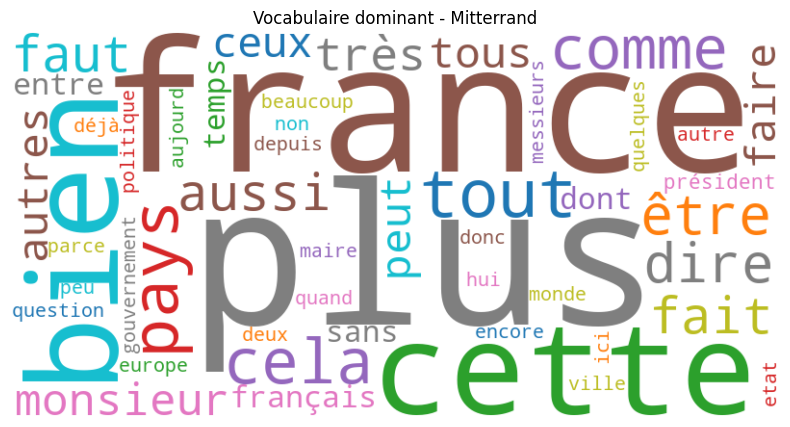

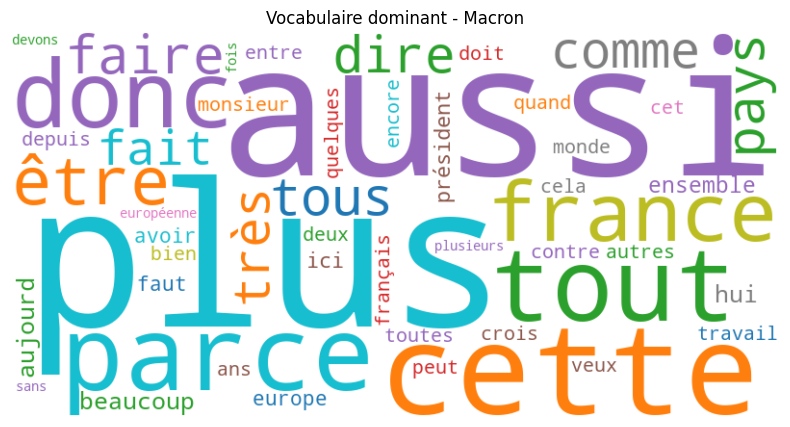

In [27]:
from collections import Counter
import ast
import re
import nltk
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Télécharger les stopwords français si nécessaire
nltk.download('stopwords')
from nltk.corpus import stopwords
stop_words = set(stopwords.words('french'))

# 1. Nettoyer la colonne 'speakers'
df['speakers'] = df['speakers'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

# 2. Extraire le président
def extract_president(speakers):
    if isinstance(speakers, list):
        for person in speakers:
            role = person.get('function', '')
            if isinstance(role, str) and 'président' in role.lower():
                return person.get('name', 'Inconnu')
    return 'Inconnu'

df['president'] = df['speakers'].apply(extract_president)

# 3. Fonction de nettoyage du texte
def clean_text(text):
    if not isinstance(text, str):
        return []
    text = text.lower()
    text = re.sub(r'[^a-zàâçéèêëîïôûùüÿñ]+', ' ', text)  # garder lettres
    words = text.split()
    return [w for w in words if w not in stop_words and len(w) > 2]

df['tokens'] = df['text'].apply(clean_text)

# 4. Comparer deux présidents (ex. De Gaulle vs Macron)
presidents_to_compare = ['Mitterrand', 'Macron']

lexical_counts = {}
for pres in presidents_to_compare:
    # Récupérer tous les tokens des textes du président
    pres_tokens = df[df['president'].str.contains(pres, case=False, na=False)]['tokens']
    all_tokens = [word for tokens in pres_tokens if isinstance(tokens, list) for word in tokens]
    lexical_counts[pres] = Counter(all_tokens).most_common(50)  # top 50 mots

# 5. Créer des nuages de mots pour visualiser les ruptures lexicales
for pres in presidents_to_compare:
    word_freq = dict(lexical_counts[pres])
    if len(word_freq) > 0:  # éviter l'erreur si pas de mots
        wc = WordCloud(width=800, height=400, background_color='white', colormap='tab10').generate_from_frequencies(word_freq)
        plt.figure(figsize=(10,5))
        plt.imshow(wc, interpolation='bilinear')
        plt.axis('off')
        plt.title(f"Vocabulaire dominant - {pres}")
        plt.show()
    else:
        print(f"Aucun mot trouvé pour {pres}")


### Interprétation des nuages de mots (Mitterrand vs Macron)

Les deux nuages illustrent les mots les plus fréquents dans les discours respectifs de François Mitterrand et d'Emmanuel Macron.

- **Mitterrand** : on voit des termes très généraux (« france », « pays », « plus », « bien », « monsieur », « président »). Cela reflète un style conventionnel, axé sur l'identité nationale et la répétition d'expressions courantes. En tant que président socialiste des années 80–90, son vocabulaire reste relativement classique et gestionnaire, insistant sur « le pays » et la « société ».

- **Macron** : le nuage contient davantage de verbes d'action (« faire », « être », « faut », « doit ») et d'adverbes liant (« aussi », « tout », « parce », « bien »). Ce registre mobilise la performance et l'urgence (« on doit faire », « il faut »), caractéristique de sa rhétorique entrepreneuriale et réformatrice. Le mot « france » reste central, mais il est entouré d'un langage plus prescriptif.

**Lecture politique** : alors que Mitterrand s’exprime comme un notable présidentiel focalisé sur le collectif et l’héritage, Macron adopte une posture de manager du changement, insistant sur l’action, la nécessité et l’engagement individuel. Ces nuages montrent la continuité sur le thème national, mais aussi la transition vers un discours plus dirigiste et orienté vers la mise en oeuvre.

### Quels mots-clés émergent après les années 2000 (ex. “numérique”, “climat”, “Europe”) ?

In [ ]:

# Télécharger les stopwords français si nécessaire
nltk.download('stopwords')
from nltk.corpus import stopwords
stop_words = set(stopwords.words('french'))

# 1. Fonction de nettoyage du texte
def clean_text(text):
    if not isinstance(text, str):
        return []
    text = text.lower()
    text = re.sub(r'[^a-zàâçéèêëîïôûùüÿñ]+', ' ', text)  # garder lettres
    words = text.split()
    return [w for w in words if w not in stop_words and len(w) > 2]

df['tokens'] = df['text'].apply(clean_text)

# 2. Filtrer uniquement les discours après 2000
df_after_2000 = df[df['year'] > 2000]   

# 3. Récupérer tous les tokens
all_tokens = [word for tokens in df_after_2000['tokens'] if isinstance(tokens, list) for word in tokens]

# 4. Compter les fréquences
word_freq = Counter(all_tokens).most_common(100)

# 5. Générer le WordCloud
wc = WordCloud(width=1000, height=500, background_color='white', colormap='tab10').generate_from_frequencies(dict(word_freq))

plt.figure(figsize=(12,6))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title("Mots-clés émergents après 2000")
plt.show()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\fangn\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


### Interprétation du nuage de mots « après 2000 »

Le nuage suivant rassemble les mots les plus fréquents dans les discours politiques post‑2000.

- Les mots dominants (« cette », « plus », « pays », « france », « être », « faire ») restent généraux, mais on note aussi beaucoup de termes liés à l’action (« faut », « doit », « faire ») et à l’organisation (« ministre », « président », « gouvernement », « entreprises »).
- Le vocabulaire reflète un discours centré sur l’opérationnel : l’État parle de projets, de loi, de cadre, de développement, d’accords et de sécurité. Les références à l’Europe ou à l’euro sont présentes mais pas dominantes, ce qui traduit une importance institutionnelle sans hégémonie.

**Lecture politique** : après 2000, le discours officiel se véhicule davantage comme une « box à outils » – mots d’ordre, obligations et structures  plutôt qu’un discours idéologique ou identitaire. L’usage fréquent de « faut » et « doit » désigne la fonction normative du politique, tandis que « cette » et « plus » servent à contextualiser des décisions. Ce nuage illustre la professionalisation et l’institutionnalisation du langage, en phase avec des gouvernances de crises et de réformes répétées.